# Week4_ex2 — 37-bus system: base case, N-1 contingency scan, sensitivities and economic dispatch

Reproduces Examples 6.13, 6.15 and 6.16 and Problems 6.52–6.54 from Glover, Overbye & Sarma, *Power System Analysis and Design* (7th ed.), on the 37-bus case shared by all of them. PowerWorld's own contingency analysis (LTC and switched-shunt control frozen) is the reference for the full N-1 scan; the problem cases are compared as saved in the case files, whose data differ slightly from the printed problems.

![PowerWorld one-line](Images/Week4_ex2_result_image.png)

In [1]:
import copy
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Case data, PowerWorld reference results and the shared solver are in case37.py next to this notebook
from case37 import (BUSES, GENS, GEN_COST, TRAFOS, SLACK_BUS, TOL_MVA, PW, PW_FLOWS, PW_YBUS, PW_CA,
                    build_case, branch, set_status, set_tap, solve_pw, gen_q, losses, amp_at, amp_loading,
                    mva_percent, residual_band, compare, summarize, bus_measure, bus_rows)

IMG = Path("Images")
IMG.mkdir(exist_ok=True)

In [2]:
# 2. Example 6.13 base case against the saved PowerWorld solution
base = solve_pw(build_case())
band = residual_band(build_case, bus_measure)
rows = bus_rows(base, PW["ex6_13"], band, "Example6_13 case")
gq = gen_q(base)
for k, (bus, gid, on, *_ ) in enumerate(GENS):
    if on and bus != SLACK_BUS:
        rows.append(("Generator Mvar", f"Q G{bus}-{gid} [Mvar]", gq[base.gen.index[base.gen.name == f"G{bus}-{gid}"][0]],
                     PW["ex6_13"]["gen_q"][k], 5e-6 + TOL_MVA, "Example6_13 case"))
rows.append(("Slack", "P G31 [MW]", base.res_ext_grid.p_mw.iloc[0], PW["ex6_13"]["gen_p"][3], 5e-6 + TOL_MVA, "Example6_13 case"))
rows.append(("Slack", "Q G31 [Mvar]", base.res_ext_grid.q_mvar.iloc[0], PW["ex6_13"]["gen_q"][3], 5e-6 + TOL_MVA, "Example6_13 case"))
base_cmp = compare(rows)
summarize(base_cmp)

,Group,Source,Rows,Max abs diff,Tightest tolerance,Smallest margin,All pass
0,Bus voltage,Example6_13 case,37,0.000007,1.200000e-07,9.000000e-08,True
1,Bus angle,Example6_13 case,37,0.000073,2.000000e-06,2.000000e-06,True
2,Generator Mvar,Example6_13 case,6,0.028548,1.000050e-01,7.145707e-02,True
3,Slack,Example6_13 case,2,0.012486,1.000050e-01,8.751861e-02,True


In [3]:
# 3. All 57 branches, both ends, against the flows PowerWorld writes into its MATPOWER export (two decimals)
def flow_measure(net):
    vals, used = {}, {}
    names = list(net.line.name) + list(net.trafo.name)
    for f, t, *_ in PW_FLOWS:
        # parallel circuits appear in circuit order in the export
        k = used[(f, t)] = used.get((f, t), 0) + 1
        name = sorted(n for n in names if n.startswith(f"{f}-{t}-"))[k - 1]
        table, i = branch(net, name)
        r = net[f"res_{table}"]
        if table == "line":
            a, b = "from", "to"
        else:
            a, b = ("hv", "lv") if net.trafo.at[i, "hv_bus"] == f else ("lv", "hv")
        vals.update({f"P {name} at {f} [MW]": r.at[i, f"p_{a}_mw"], f"Q {name} at {f} [Mvar]": r.at[i, f"q_{a}_mvar"],
                     f"P {name} at {t} [MW]": r.at[i, f"p_{b}_mw"], f"Q {name} at {t} [Mvar]": r.at[i, f"q_{b}_mvar"]})
    return pd.Series(vals)


band = residual_band(build_case, flow_measure)
got = flow_measure(base)
ref = [x for f, t, pf, qf, pt, qt in PW_FLOWS for x in (pf, qf, pt, qt)]
rows = [("Branch P" if q.startswith("P") else "Branch Q", q, got[q], r, 5e-3 + band[q], "Example6_13 MATPOWER export")
        for q, r in zip(got.index, ref)]
flow_cmp = compare(rows)
summarize(flow_cmp)

,Group,Source,Rows,Max abs diff,Tightest tolerance,Smallest margin,All pass
0,Branch P,Example6_13 MATPOWER export,114,0.005515,0.054943,0.051864,True
1,Branch Q,Example6_13 MATPOWER export,114,0.013716,0.036158,0.031922,True


In [4]:
# 4. Example 6.16: Ybus of the 37-bus case, entry by entry, and how sparse it is
lookup = base._pd2ppc_lookups["bus"]
order = [lookup[num] for num, _, _ in BUSES]
Y = base._ppc["internal"]["Ybus"].toarray()[np.ix_(order, order)]
Ypw = np.zeros_like(Y)
for r, c, g, b in PW_YBUS:
    Ypw[r - 1, c - 1] = g + 1j * b
# the export prints four decimals (5e-5) from single-precision values (spacing up to 3e-5 near 240). On the tap side of an off-nominal transformer PowerWorld keeps half of the
# magnetizing B without the 1/t^2 scaling, which shifts that diagonal by B/2 * (1 - 1/t^2): 2e-4 pu at OAK69
tap_shift = {num: 0.0 for num, _, _ in BUSES}
for f, t, ckt, r, x, b, tap, lim in TRAFOS:
    tap_shift[f] += abs(b) / 2 * abs(1 - 1 / tap ** 2)
pos = {k + 1: num for k, (num, _, _) in enumerate(BUSES)}
f32 = lambda v: float(np.spacing(np.float32(abs(v))))
rows = [("Ybus G", f"G({r},{c})", Y[r - 1, c - 1].real, g, 5e-5 + f32(g), "Example6_13 Ybus export") for r, c, g, b in PW_YBUS]
rows += [("Ybus B", f"B({r},{c})", Y[r - 1, c - 1].imag, b, 5e-5 + f32(b) + (tap_shift[pos[r]] if r == c else 0.0),
          "Example6_13 Ybus export") for r, c, g, b in PW_YBUS]
ybus_cmp = compare(rows)
assert ((np.abs(Y) > 1e-9) == (np.abs(Ypw) > 0)).all()       # identical sparsity pattern
pd.DataFrame({
    "Quantity": ["Buses", "Ybus entries", "Nonzero entries", "Nonzero share [%]", "Max |Y - Y_PW| [pu]", "Same pattern"],
    "Value": [len(BUSES), Y.size, int((np.abs(Y) > 1e-9).sum()), round((np.abs(Y) > 1e-9).mean() * 100, 1),
              round(np.abs(Y - Ypw).max(), 6), True],
})

,Quantity,Value
0,Buses,37
1,Ybus entries,1369
2,Nonzero entries,135
3,Nonzero share [%],9.9
4,Max |Y - Y_PW| [pu],0.000224
5,Same pattern,True


In [5]:
# 5. Example 6.13: open OAK69-WALNUT69. PowerWorld's LTCs stepped the two OAK transformers from 1.025 to 1.0125,
#     so that tap state is applied before comparing; the textbook figures are the ones printed with the example
def build_open():
    net = build_case()
    set_status(net, "12-18-1", False)
    for k, (f, t, ckt, *_ ) in enumerate(TRAFOS):
        set_tap(net, f"{f}-{t}-{ckt}", PW["ex6_13_open"]["taps"][k])
    return net


opened = solve_pw(build_open())
band = residual_band(build_open, bus_measure)
rows = bus_rows(opened, PW["ex6_13_open"], band, "Example6_13 case, line opened")
mva_band = residual_band(build_open, lambda n: pd.Series({"5-44": mva_percent(n, "5-44-1")}))
rows += [
    ("Textbook", "V 37 [pu]", opened.res_bus.vm_pu[37], 0.911, 5e-4 + band["V 37 [pu]"], "Example 6.13 text"),
    ("Textbook", "POPLAR69-PEACH69 [% of MVA limit]", mva_percent(opened, "5-44-1"), 135, 0.5 + mva_band["5-44"], "Example 6.13 text"),
]
open_cmp = compare(rows)
summarize(open_cmp)

,Group,Source,Rows,Max abs diff,Tightest tolerance,Smallest margin,All pass
0,Bus voltage,"Example6_13 case, line opened",37,0.000014,1.200000e-07,9.000000e-08,True
1,Bus angle,"Example6_13 case, line opened",37,0.000179,2.000000e-06,2.000000e-06,True
2,Textbook,Example 6.13 text,2,0.381443,1.949932e-03,1.764853e-03,True


In [6]:
# 6. Example 6.15: one PEACH transformer and CHERRY-OLIVE out of service; generator sensitivities of the
#     overloaded transformer are measured on its MVA flow at the PEACH138 end, as PowerWorld reports them
def peach_mva(net):
    _, i = branch(net, "44-41-1")
    r = net.res_trafo
    return np.hypot(r.at[i, "p_hv_mw"], r.at[i, "q_hv_mvar"])


def with_gen(case, gen, mw):
    net = build_case(case)
    net.gen.loc[net.gen.name.isin(gen if isinstance(gen, list) else [gen]), "p_mw"] = mw
    return solve_pw(net)


c615 = solve_pw(build_case("6_15"))
band = residual_band(lambda: build_case("6_15"), bus_measure)
rows = bus_rows(c615, PW["ex6_15"], band, "Example6_15 case")


def sens_measure(net):
    # 1 MW finite difference on top of whatever state the network is in
    out = {"S": peach_mva(net)}
    for g in ["G44-1", "G28-1"]:
        m = copy.deepcopy(net)
        m.gen.loc[m.gen.name == g, "p_mw"] += 1.0
        out[g] = peach_mva(solve_pw(m)) - out["S"]
    return pd.Series(out)


sens = sens_measure(c615)
sband = residual_band(lambda: build_case("6_15"), sens_measure)
rows += [
    ("Textbook", "PEACH69-PEACH138 #1 [% of MVA limit]", sens["S"] / 101 * 100, 115, 0.5 + sband["S"] / 101 * 100, "Example 6.15 one-line"),
    ("Textbook", "dS/dP PEACH69 gen [MVA/MW]", sens["G44-1"], -0.508, 5e-4 + sband["G44-1"], "Example 6.15 sensitivities"),
    ("Textbook", "dS/dP ELM345 gen [MVA/MW]", sens["G28-1"], 0.033, 5e-4 + sband["G28-1"], "Example 6.15 sensitivities"),
]
c615_cmp = compare(rows)

# bisect the PEACH69 output that brings the transformer back to its limit; dropping ELM345 to zero cannot
lo, hi = 20.0, 150.0
for _ in range(40):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if peach_mva(with_gen("6_15", "G44-1", mid)) > 101 else (lo, mid)
elm_zero = peach_mva(with_gen("6_15", ["G28-1", "G28-2"], 0.0)) / 101 * 100
assert elm_zero > 100
display(summarize(c615_cmp))
pd.DataFrame({
    "Remedy": ["Raise PEACH69 generation until the transformer is at 100%", "Take both ELM345 units to 0 MW"],
    "Result": [f"{hi:.1f} MW (from 20 MW)", f"{elm_zero:.1f}% - still overloaded"],
})

,Group,Source,Rows,Max abs diff,Tightest tolerance,Smallest margin,All pass
0,Bus voltage,Example6_15 case,37,0.000008,1.200000e-07,9.000000e-08,True
1,Bus angle,Example6_15 case,37,0.000124,2.000000e-06,2.000000e-06,True
2,Textbook,Example 6.15 one-line,1,0.009611,1.215875e+00,1.206264e+00,True
3,Textbook,Example 6.15 sensitivities,2,0.000203,5.738519e-04,3.709061e-04,True


,Remedy,Result
0,Raise PEACH69 generation until the transformer...,49.9 MW (from 20 MW)
1,Take both ELM345 units to 0 MW,105.1% - still overloaded


In [7]:
# 7. Full N-1 scan (43 lines + 14 transformers) with taps and switched shunts frozen, against PowerWorld CA.
#     Limits: branch current at nominal voltage above 100% of the MVA rating, bus voltage below 0.95 pu
def run_n1(build=build_case):
    out, failed = [], []
    for name in list(build().line.name) + list(build().trafo.name):
        net = build()
        set_status(net, name, False)
        try:
            solve_pw(net)
        except Exception:
            failed.append(name)
            continue
        load = amp_loading(net)
        for el, pct in load[load > 100].items():
            out.append((name, f"branch {el}", pct))
        v = net.res_bus.vm_pu
        for b, x in v[v < 0.95].items():
            out.append((name, f"bus {b}", x))
    return pd.DataFrame(out, columns=["Outage", "Element", "Value"]), failed


def ca_outage(ctg):
    # names look like L_000012OAK69-000018WALNUT69C1: six-digit bus numbers, circuit after the last "C"
    a, b = re.match(r"[LT]_(\d{6})[^-]*-(\d{6})", ctg).groups()
    a, b, ckt = int(a), int(b), ctg.rsplit("C", 1)[1]
    names = list(base.line.name) + list(base.trafo.name)
    return next(n for n in (f"{a}-{b}-{ckt}", f"{b}-{a}-{ckt}") if n in names)


n1, failed = run_n1()
assert not failed

# what PowerWorld reports per outage, measured the same way in pandapower
monitored = {}
for ctg, element, kind, value, limit, pct in PW_CA:
    tok = element.split()
    item = ("bus", int(tok[1])) if kind == "Bus Low Volts" else ("branch", f"{tok[1]}-{tok[2]}-{tok[3]}", int(tok[4]))
    monitored.setdefault(ca_outage(ctg), []).append((item, value, pct))


def outage_measure(items):
    def measure(net):
        vals = {}
        for item, *_ in items:
            if item[0] == "bus":
                vals[f"V {item[1]}"] = net.res_bus.vm_pu[item[1]]
            else:
                vals[f"A {item[1]}"], vals[f"% {item[1]}"] = amp_at(net, item[1], item[2])
        return pd.Series(vals)
    return measure


rows, keys = [], set()
for outage, items in monitored.items():
    def build_out(o=outage):
        net = build_case()
        set_status(net, o, False)
        return net
    measure = outage_measure(items)
    bnd = residual_band(build_out, measure)
    got = measure(solve_pw(build_out()))
    for item, value, pct in items:
        if item[0] == "bus":
            rows.append(("Low voltage", f"{outage} out: V {item[1]} [pu]", got[f"V {item[1]}"], value,
                         5e-5 + bnd[f"V {item[1]}"], "PowerWorld CA"))
            keys.add((outage, f"bus {item[1]}"))
        else:
            rows += [("Overload current", f"{outage} out: {item[1]} at {item[2]} [A]", got[f"A {item[1]}"], value,
                      5e-4 + bnd[f"A {item[1]}"], "PowerWorld CA"),
                     ("Overload percent", f"{outage} out: {item[1]} [%]", got[f"% {item[1]}"], pct,
                      5e-4 + bnd[f"% {item[1]}"], "PowerWorld CA")]
            keys.add((outage, f"branch {item[1]}"))
assert set(zip(n1.Outage, n1.Element)) == keys          # same violations, nothing missing, nothing extra
ca_cmp = compare(rows)
ca_cmp[["Quantity", "pandapower", "Reference", "Abs diff", "Tolerance", "Pass"]].round(4)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass
0,12-18-1 out: 5-18-1 at 18 [A],780.6579,780.3670,0.2909,3.2930,True
1,12-18-1 out: 5-18-1 [%],113.7776,113.7350,0.0426,0.4804,True
2,12-18-1 out: 5-44-1 at 5 [A],918.0442,917.7120,0.3322,4.4803,True
3,12-18-1 out: 5-44-1 [%],133.8010,133.7530,0.0480,0.6534,True
4,12-18-1 out: V 18 [pu],0.9119,0.9119,0.0000,0.0015,True
5,12-18-1 out: V 37 [pu],0.9098,0.9098,0.0000,0.0015,True
6,48-47-1 out: 48-54-1 at 48 [A],731.8063,731.8260,0.0197,4.5974,True
7,48-47-1 out: 48-54-1 [%],105.3726,105.3750,0.0024,0.6624,True
8,10-13-1 out: 54-55-1 at 55 [A],600.3356,600.2830,0.0526,2.3472,True
9,10-13-1 out: 54-55-1 [%],143.4940,143.4810,0.0130,0.5614,True


In [8]:
# 8. Ranking: the contingency the textbook walks through is not the worst one
names = list(base.line.name) + list(base.trafo.name)
rank = []
for name in names:
    net = build_case()
    set_status(net, name, False)
    solve_pw(net)
    load = amp_loading(net)
    rank.append({"Outage": name, "Max loading [%]": load.max(), "Most loaded": load.idxmax(),
                 "Min voltage [pu]": net.res_bus.vm_pu.min(), "Lowest bus": int(net.res_bus.vm_pu.idxmin()),
                 "Violations": int((load > 100).sum() + (net.res_bus.vm_pu < 0.95).sum())})
pd.DataFrame(rank).sort_values("Max loading [%]", ascending=False).head(6).round(3)

,Outage,Max loading [%],Most loaded,Min voltage [pu],Lowest bus,Violations
5,10-13-1,143.494,54-55-1,0.945,13,2
8,12-18-1,133.801,5-44-1,0.910,37,4
44,10-39-1,132.439,54-55-1,0.956,13,1
55,48-47-1,105.373,48-54-1,0.985,21,1
4,5-44-1,97.311,12-18-1,0.967,5,0
10,13-55-1,96.792,54-55-1,0.970,55,0


In [9]:
# 9. Problem 6.52 (saved case: REDBUD69 capacitor fixed, 1 Mvar steps): open REDBUD69-PEACH69 and size the
#     REDBUD69 capacitor that holds the bus at 1.0 pu
c652 = solve_pw(build_case("6_52"))
band = residual_band(lambda: build_case("6_52"), bus_measure)
c652_cmp = compare(bus_rows(c652, PW["p6_52"], band, "Problem6_52 case"))
assert c652_cmp.Pass.all()

sweep = []
for mvar in range(5, 31):
    net = build_case("6_52")
    set_status(net, "14-44-1", False)
    net.shunt.loc[net.shunt.name == "SS14", "q_mvar"] = -mvar
    solve_pw(net)
    sweep.append({"Capacitor [Mvar]": mvar, "V REDBUD69 [pu]": net.res_bus.vm_pu[14], "Losses [MW]": losses(net)})
sweep = pd.DataFrame(sweep)
need = sweep.loc[sweep["V REDBUD69 [pu]"] >= 1.0, "Capacitor [Mvar]"].min()
sweep[sweep["Capacitor [Mvar]"].isin([5, need - 1, need, need + 1])].round(4)

,Capacitor [Mvar],V REDBUD69 [pu],Losses [MW]
0,5,0.9646,12.7486
21,26,0.9997,12.7499
22,27,1.0014,12.7675
23,28,1.0032,12.7868


In [10]:
# 10. Problem 6.53 runs the area on economic dispatch: AGC units share each change at equal incremental cost,
#     corrected by loss penalty factors (slack bus as reference). Units at a limit stay there; the slack takes the rest
GEN_ROW = {(f"G{b}" if b == SLACK_BUS else f"G{b}-{gid}"): k for k, (b, gid, *_ ) in enumerate(GENS)}


def agc_units(net):
    units = [g for g in net.gen.index if net.gen.at[g, "pv_on"] and GENS[GEN_ROW[net.gen.at[g, "name"]]][7]]
    return units + ["slack"]


def unit_p(net, u):
    return net.res_ext_grid.p_mw.iloc[0] if u == "slack" else net.gen.at[u, "p_mw"]


def unit_data(u, net):
    k = GEN_ROW[f"G{SLACK_BUS}"] if u == "slack" else GEN_ROW[net.gen.at[u, "name"]]
    c2, c1, _ = GEN_COST[k]
    return c2, c1, GENS[k][8], GENS[k][9]


def economic_dispatch(net, iters=30):
    units = agc_units(net)
    pf = {u: 1.0 for u in units}
    for _ in range(iters):
        solve_pw(net)
        demand = sum(unit_p(net, u) for u in units)
        base_loss = losses(net)
        for u in units[:-1]:
            p0 = net.gen.at[u, "p_mw"]
            net.gen.at[u, "p_mw"] = p0 + 1.0
            pf[u] = 1.0 / (1.0 - (losses(solve_pw(net)) - base_loss))
            net.gen.at[u, "p_mw"] = p0
        data = {u: unit_data(u, net) for u in units}
        dispatch = lambda lam: {u: min(max((lam / pf[u] - data[u][1]) / (2 * data[u][0]), data[u][2]), data[u][3])
                                for u in units}
        lo, hi = 0.0, 500.0
        for _ in range(80):
            lam = (lo + hi) / 2
            lo, hi = (lo, lam) if sum(dispatch(lam).values()) > demand else (lam, hi)
        target = dispatch(lam)
        step = max(abs(target[u] - net.gen.at[u, "p_mw"]) for u in units[:-1])
        for u in units[:-1]:
            net.gen.at[u, "p_mw"] = target[u]
        if step < 1e-3:
            break
    return solve_pw(net)


def pw_state(key):
    net = build_case("6_53")
    for g in net.gen.index:
        net.gen.at[g, "p_mw"] = PW[key]["gen_p"][GEN_ROW[net.gen.at[g, "name"]]]
    for k, (f, t, ckt, *_ ) in enumerate(TRAFOS):
        set_tap(net, f"{f}-{t}-{ckt}", PW[key]["taps"][k])
    return solve_pw(net)


rows, split = [], []
for key, p53, summary_loss in (("p6_53_P0", 0.0, 14.3), ("p6_53_P260", 260.0, None)):
    state = pw_state(key)
    net = build_case("6_53")
    net.gen.loc[net.gen.name == "G53-1", "p_mw"] = p53
    ed = economic_dispatch(net)
    agc = agc_units(ed)
    # PowerWorld stops redispatching once the area error is inside its 5 MW AGC tolerance
    rows.append(("Dispatch", f"PEAR138={p53:.0f}: AGC units total [MW]", sum(unit_p(ed, u) for u in agc),
                 sum(unit_p(state, u) for u in agc), 5.0, f"{key} case"))
    rows.append(("State", f"PEAR138={p53:.0f}: max |V - V_PW| at PowerWorld's dispatch [pu]",
                 max(abs(state.res_bus.vm_pu[b] - PW[key]["vm"][k]) for k, (b, _, _) in enumerate(BUSES)), 0.0, 1e-4, f"{key} case"))
    if summary_loss is not None:
        rows.append(("State", f"PEAR138={p53:.0f}: losses at PowerWorld's dispatch [MW]", losses(state), summary_loss,
                     0.05 + TOL_MVA, "Case Summary"))
    else:
        # losses are flat around the optimum, so a different split of the same total costs almost nothing
        rows.append(("Dispatch", f"PEAR138={p53:.0f}: losses, own dispatch vs PowerWorld's [MW]", losses(ed), losses(state),
                     TOL_MVA, f"{key} case"))
    for u in agc:
        c2, c1, _, _ = unit_data(u, ed)
        name = "G31 (slack)" if u == "slack" else ed.gen.name[u]
        split.append({"PEAR138 [MW]": p53, "Unit": name, "pandapower [MW]": unit_p(ed, u), "PowerWorld [MW]": unit_p(state, u),
                      "Incremental cost PW [$/MWh]": 2 * c2 * unit_p(state, u) + c1})
ed_cmp = compare(rows)
display(ed_cmp[["Quantity", "pandapower", "Reference", "Abs diff", "Tolerance", "Pass", "Source"]].round(5))
# the two ELM345 units share a bus, so an optimal split gives them the same incremental cost; PowerWorld's
# 17.24 against 17.38 $/MWh shows it stopped inside its AGC tolerance rather than at the optimum
pd.DataFrame(split).round(3)

,Quantity,pandapower,Reference,Abs diff,Tolerance,Pass,Source
0,PEAR138=0: AGC units total [MW],680.05039,680.42825,0.37786,5.0000,True,p6_53_P0 case
1,PEAR138=0: max |V - V_PW| at PowerWorld's disp...,0.00001,0.00000,0.00001,0.0001,True,p6_53_P0 case
2,PEAR138=0: losses at PowerWorld's dispatch [MW],14.30564,14.30000,0.00564,0.1500,True,Case Summary
3,PEAR138=260: AGC units total [MW],416.41391,416.43338,0.01947,5.0000,True,p6_53_P260 case
4,PEAR138=260: max |V - V_PW| at PowerWorld's di...,0.00001,0.00000,0.00001,0.0001,True,p6_53_P260 case
5,"PEAR138=260: losses, own dispatch vs PowerWorl...",10.27418,10.29369,0.01951,0.1000,True,p6_53_P260 case


,PEAR138 [MW],Unit,pandapower [MW],PowerWorld [MW],Incremental cost PW [$/MWh]
0,0.0,G28-1,150.000,150.000,17.600
1,0.0,G28-2,150.000,150.000,17.500
2,0.0,G44-1,150.000,150.000,32.800
3,0.0,G31 (slack),230.050,230.428,19.830
4,260.0,G28-1,129.528,127.481,17.240
5,260.0,G28-2,138.622,143.850,17.377
6,260.0,G44-1,20.000,20.000,26.040
7,260.0,G31 (slack),128.264,125.103,17.302


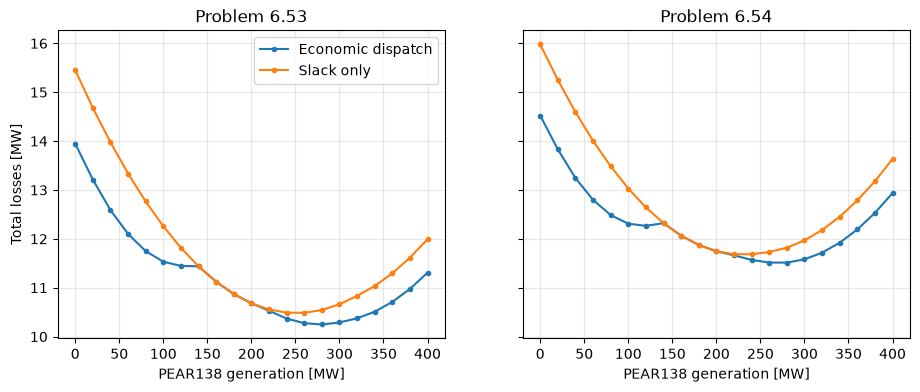

,Problem,Rule,PEAR138 [MW],Losses [MW],Max loading [%]
0,6.53,Economic dispatch,280,10.247,83.137
1,6.53,Slack only,260,10.486,80.116
2,6.54,Economic dispatch,280,11.513,89.710
3,6.54,Slack only,220,11.685,86.144


In [11]:
# 11. Problems 6.53 and 6.54: PEAR138 from 0 to 400 MW, total losses under two dispatch rules
#     (taps frozen at the saved case; 6.54 removes LOCUST69-PEAR69)
rows = []
for problem, outage in (("6.53", None), ("6.54", "54-55-1")):
    for p53 in range(0, 401, 20):
        for rule in ("Slack only", "Economic dispatch"):
            net = build_case("6_53")
            if outage:
                set_status(net, outage, False)
            net.gen.loc[net.gen.name == "G53-1", "p_mw"] = p53
            net = economic_dispatch(net) if rule == "Economic dispatch" else solve_pw(net)
            rows.append({"Problem": problem, "Rule": rule, "PEAR138 [MW]": p53, "Losses [MW]": losses(net),
                         "Max loading [%]": amp_loading(net).max()})
loss_sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (problem, g) in zip(axes, loss_sweep.groupby("Problem")):
    for rule, h in g.groupby("Rule"):
        ax.plot(h["PEAR138 [MW]"], h["Losses [MW]"], marker="o", ms=3, label=rule)
    ax.set_title(f"Problem {problem}")
    ax.set_xlabel("PEAR138 generation [MW]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Total losses [MW]")
axes[0].legend()
fig.savefig(IMG / "Week4_ex2_pear138_loss_dispatch_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

best = loss_sweep.loc[loss_sweep.groupby(["Problem", "Rule"])["Losses [MW]"].idxmin()]
best.round(3).reset_index(drop=True)